# LLM Classification Finetuning - improved classical pipeline (same MiniLM, no transformer fine-tuning)

**What this notebook does (your 7-step plan):**
1. **Integrity** - one-hot labels, label-mapping sanity test, duplicates, prompt-disjoint stratified folds.
2. **Character TF-IDF + pairwise relevance** - char n-gram and word TF-IDF cosine (prompt-response, A-B), keyword overlap, MiniLM cosines.
3. **Log transforms and normalised differences** - `(A-B)/(A+B+1)` and `log1p(A)-log1p(B)` for all count features.
4. **LightGBM** - feature-group ablation + small random search on fold 0.
5. **Out-of-fold predictions** for every training row (5 prompt-grouped folds), test predictions averaged over folds.
6. **Blend** two LightGBMs + a sparse TF-IDF logistic regression + a MiniLM-vector logistic regression, weights fitted on OOF.
7. **Calibration** (temperature + tie bias, CV-checked) and `submission.csv`.

**Speed-ups vs. the old notebook:** every distinct response is processed once and swapped (A<->B) copies are built by re-indexing, not by re-running feature extraction; text statistics and TF-IDF run in parallel; embeddings are de-duplicated and cached; no re-training on the full data (test predictions come from the fold models); fixed round count after fold 0 (no early-stopping on every fold).

**What changed in this version (goal: ~0.95 log loss instead of ~1.00):** the classical pipeline alone plateaus around 0.99-1.00, so after it the notebook now **fine-tunes a small decoder LLM (LoRA + classification head) inside the notebook, offline**, on the competition data, and blends it with the classical stack on a held-out set. Training is time-boxed by wall clock (so the run always ends inside `TOTAL_BUDGET_MIN`, default 330 min < 6 h), and if anything fails the notebook falls back to the classical submission instead of crashing.

**Before you run it:** attach a decoder LLM as an *input model* (Add Input -> Models -> e.g. `Qwen2.5` -> Transformers -> `1.5b-instruct`). The notebook finds it automatically. Run once with `LLM_CFG['DEBUG']=True` (a few minutes) to check it works, then switch to `False` for the real run.

Set `CFG` below to trade time for accuracy (e.g. `N_FOLDS=3`, `RUN_ABLATION=False`, `GBM_VARIANT_B=False` is roughly 2x faster).

In [3]:
import os, re, json, time, gc, string, hashlib, warnings
os.environ["HF_HUB_OFFLINE"] = "1"; os.environ["TRANSFORMERS_OFFLINE"] = "1"   # never try to reach the internet
from collections import Counter
import numpy as np, pandas as pd, scipy.sparse as sp
from joblib import Parallel, delayed
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
warnings.filterwarnings("ignore")

T0 = time.time()
def tick(msg): print(f"[{(time.time()-T0)/60:6.1f} min] {msg}", flush=True)

# ------------------------------------------------------------------ CONFIG (one place)
CFG = dict(
    N_FOLDS=3, SEED=42, N_JOBS=max(1, os.cpu_count() or 1),
    WORD_CHARS=(1200, 800), CHAR_CHARS=(600, 400),          # head/tail characters kept for TF-IDF
    EMB_RESP_CHARS=(600, 400), EMB_PROMPT_CHARS=(300, 200), # head/tail characters sent to MiniLM
    TFIDF_FIT_DOCS=30000,
    RUN_ABLATION=False, RUN_TUNING=False, TUNE_TRIALS=3,
    GBM_LR_SEARCH=0.08, GBM_LR_FINAL=0.04,
    GBM_VARIANT_B=False, USE_SPARSE_LR=True, USE_EMB_LR=True,
)
WORK = os.environ.get("LLM_WORK", "/kaggle/working")
os.makedirs(WORK, exist_ok=True)

def find_data_dir():
    d = os.environ.get("LLM_DATA_DIR")
    if d: return d
    for d in ["/kaggle/input/competitions/llm-classification-finetuning", "/kaggle/input/llm-classification-finetuning"]:
        if os.path.exists(f"{d}/train.csv"): return d
    for root, _, files in os.walk("/kaggle/input"):
        if "train.csv" in files and "test.csv" in files: return root
    raise FileNotFoundError("train.csv not found - attach the competition data")
DATA_DIR = find_data_dir()

LABEL_COLS = ["winner_model_a", "winner_model_b", "winner_tie"]    # class 0 = A wins, 1 = B wins, 2 = tie
SWAP = np.array([1, 0, 2])                                          # swap A<->B, tie unchanged

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def ll(p, y):                       # fast multiclass log loss (rows of p must sum to 1)
    return float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], 1e-7, 1.0))))
def tta(p_orig, p_swapped):         # average original + swapped prediction (swapped mapped back to A/B order)
    return (p_orig + p_swapped[:, SWAP]) / 2

print("data dir:", DATA_DIR, "| work dir:", WORK, "| cpus:", CFG["N_JOBS"])


data dir: /kaggle/input/competitions/llm-classification-finetuning | work dir: /kaggle/working | cpus: 4


## Step 1 - Load, verify label mapping, dataset integrity and the validation split
Checks column order, one-hot labels, ids, parses the JSON turns, asserts that `A wins` rows have the largest A-B length gap (mapping sanity), reports duplicates and prompt overlap, and builds **stratified, prompt-grouped K-fold** (a plain random split lets the same prompt sit on both sides).

In [4]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
n_tr, n_te = len(train), len(test); n_all = n_tr + n_te
print("train / test / sample_submission:", train.shape, test.shape, sample_submission.shape)

# ---- structural checks
assert list(sample_submission.columns) == ["id"] + LABEL_COLS, "unexpected submission columns/order"
for c in ["id", "prompt", "response_a", "response_b"]: assert c in test.columns, f"test missing {c}"
assert train["id"].is_unique and test["id"].is_unique, "duplicate ids"
assert len(sample_submission) == n_te and (sample_submission["id"].values == test["id"].values).all(), "sample_submission ids != test ids"
if set(train["id"]) & set(test["id"]): print("WARNING: some test ids also appear in train (ok for the 3-row placeholder test)")
print("missing values  train:", int(train[["prompt","response_a","response_b"]].isna().sum().sum()),
      "| test:", int(test[["prompt","response_a","response_b"]].isna().sum().sum()))

# ---- labels: one-hot and mapping
assert train[LABEL_COLS].isin([0, 1]).all().all() and (train[LABEL_COLS].sum(axis=1) == 1).all(), "labels not one-hot"
train["target"] = train[LABEL_COLS].values.argmax(1)
y = train["target"].values.astype(int)
print("class shares (A, B, tie):", (np.bincount(y) / n_tr).round(4))

# ---- parse the JSON-encoded turns (robust to null / malformed values)
def parse_turns(s):
    if not isinstance(s, str): return [""]
    try: v = json.loads(s)
    except Exception: return [s] if s.strip() else [""]
    if isinstance(v, str): return [v]
    if not isinstance(v, list): return [str(v)]
    return ["" if t is None else str(t) for t in v] or [""]
def join_turns(turns): return "\n\n".join(t.strip() for t in turns)

ALL = pd.concat([train[["prompt", "response_a", "response_b"]], test[["prompt", "response_a", "response_b"]]], ignore_index=True)
P_turns = [parse_turns(s) for s in ALL["prompt"]]
n_turns = np.array([len(t) for t in P_turns], dtype=np.float32)
P_all = [join_turns(t) for t in P_turns]
A_all = [join_turns(parse_turns(s)) for s in ALL["response_a"]]
B_all = [join_turns(parse_turns(s)) for s in ALL["response_b"]]
del P_turns

# ---- label-mapping sanity: the winner should on average be the LONGER answer in this dataset
len_diff = np.array([len(a) - len(b) for a, b in zip(A_all[:n_tr], B_all[:n_tr])])
m0, m1, m2 = len_diff[y == 0].mean(), len_diff[y == 1].mean(), len_diff[y == 2].mean()
print(f"mean len(A)-len(B) | A wins: {m0:+.0f} | B wins: {m1:+.0f} | tie: {m2:+.0f}")
assert m0 > m2 > m1, "label mapping looks wrong (A-win rows should have the largest A-B length gap)"

# ---- duplicates / identical responses
dup_rows = int(train.duplicated(["prompt", "response_a", "response_b"]).sum())
ident = np.array([a.strip() == b.strip() for a, b in zip(A_all[:n_tr], B_all[:n_tr])])
print(f"duplicate (prompt,A,B) rows: {dup_rows} | identical A==B rows: {ident.sum()} "
      f"(tie rate among them: {(y[ident] == 2).mean() if ident.any() else float('nan'):.3f})")
print(f"test prompts that also occur in train: {test['prompt'].isin(set(train['prompt'])).mean():.2%}")

# ---- validation split: group by prompt so the same prompt never sits on both sides
groups = pd.factorize(train["prompt"])[0]
rows_sharing_prompt = pd.Series(groups).map(pd.Series(groups).value_counts()).gt(1).mean()
rs = np.random.RandomState(0); msk = rs.rand(n_tr) < 0.2
leak = np.isin(groups[msk], groups[~msk]).mean()
print(f"rows whose prompt appears in >1 row: {rows_sharing_prompt:.2%} | a plain random 20% split would leak prompts for {leak:.2%} of its val rows")

K = CFG["N_FOLDS"]
fold_id = np.full(n_tr, -1)
for k, (_, va) in enumerate(StratifiedGroupKFold(K, shuffle=True, random_state=CFG["SEED"]).split(np.zeros(n_tr), y, groups)):
    fold_id[va] = k
assert (fold_id >= 0).all()
for k in range(K):
    assert not (set(groups[fold_id == k]) & set(groups[fold_id != k])), "prompt leakage between folds"
print("fold sizes:", np.bincount(fold_id), "| fold class shares (A,B,tie):",
      [tuple((np.bincount(y[fold_id == k], minlength=3) / (fold_id == k).sum()).round(3)) for k in range(K)][:3], "...")
print("-> split verified: stratified, prompt-disjoint, every train row gets exactly one out-of-fold prediction")
tick("data checks done")


train / test / sample_submission: (57477, 9) (3, 4) (3, 4)
missing values  train: 0 | test: 0
class shares (A, B, tie): [0.3491 0.3419 0.309 ]
mean len(A)-len(B) | A wins: +249 | B wins: -269 | tie: -5
duplicate (prompt,A,B) rows: 71 | identical A==B rows: 275 (tie rate among them: 0.902)
test prompts that also occur in train: 33.33%
rows whose prompt appears in >1 row: 15.42% | a plain random 20% split would leak prompts for 13.63% of its val rows
fold sizes: [19348 19126 19003] | fold class shares (A,B,tie): [(np.float64(0.344), np.float64(0.343), np.float64(0.313)), (np.float64(0.354), np.float64(0.339), np.float64(0.307)), (np.float64(0.349), np.float64(0.343), np.float64(0.308))] ...
-> split verified: stratified, prompt-disjoint, every train row gets exactly one out-of-fold prediction
[   0.2 min] data checks done


## Per-response statistics (computed once per unique text, in parallel)
25 style/structure statistics per response (length, bullets, code, headers, refusals, hedges, readability, ...), prompt statistics, keyword overlap and A-B word Jaccard.

In [5]:
WORD_RE = re.compile(r"[A-Za-z0-9']+")
SENT_SPLIT = re.compile(r'(?<=[.!?])\s+|\n+')
PARA_SPLIT = re.compile(r'\n\s*\n')
VOWELS = re.compile(r'[aeiouy]+')
UPPER_RE, ALPHA_RE, DIGIT_RE = re.compile(r"[A-Z]"), re.compile(r"[A-Za-z]"), re.compile(r"\d")
NONASCII_RE = re.compile(r"[^\x00-\x7f]")
URL_RE = re.compile(r"https?://")
BULLET_RE = re.compile(r"(?m)^\s*(?:[-*\u2022]|\d+[.)])\s")
HEADER_RE = re.compile(r"(?m)^#{1,6}\s")
SELF_REF_RE = re.compile(r"\b(i|i'm|i've|i'll|i'd|my|me|myself)\b", re.I)
SELF_PROMO_RE = re.compile(r"(as an ai|language model|i am designed|i'm designed|i can help|i'm here to|happy to help|my training|my capabilities|i was trained|developed by|openai|anthropic)", re.I)
REFUSAL_RE = re.compile(r"(i can't|i cannot|i'm sorry|i am sorry|as an ai|i apologize|i'm unable|i am unable)", re.I)
HEDGE_RE = re.compile(r"\b(however|it's important|it is important|please note|keep in mind|note that|generally|typically|may vary|depends)\b", re.I)
CODE_RE = re.compile(r"(```|\bdef |\bfunction\b|#include|\bSELECT\b|\bimport \w+|</?[a-z]+>|\{.*\})")
PUNCT_TABLE = str.maketrans("", "", string.punctuation)
STOP = ENGLISH_STOP_WORDS

RESP_NAMES = ["char_count", "word_count", "sentence_count", "paragraph_count", "avg_sentence_length", "readability",
              "punctuation_count", "repeated_word_ratio", "unique_word_ratio", "capitalization_ratio",
              "self_reference", "self_promotion", "avg_word_length", "newline_count", "digit_ratio",
              "question_marks", "exclaims", "url_count", "bullets", "code_blocks", "bold", "headers",
              "refusal", "hedges", "non_ascii_ratio"]
PROMPT_NAMES = ["chars", "words", "qmarks", "newlines", "code", "digit_ratio", "nonascii_ratio", "turns"]

def resp_stats(t):
    words = WORD_RE.findall(t); n = len(words); nch = len(t)
    cnt = Counter(w.lower() for w in words)
    ns = max(sum(1 for s in SENT_SPLIT.split(t) if s.strip()), 1)
    npar = max(sum(1 for p in PARA_SPLIT.split(t) if p.strip()), 1)
    alpha = len(ALPHA_RE.findall(t))
    syll = max(len(VOWELS.findall(t.lower())), n)
    flesch = 206.835 - 1.015 * (n / ns) - 84.6 * (syll / n) if n else 0.0
    return [nch, n, ns, npar, n / ns, flesch, nch - len(t.translate(PUNCT_TABLE)),
            (sum(c for c in cnt.values() if c > 1) / n) if n else 0.0,
            (len(cnt) / n) if n else 0.0,
            (len(UPPER_RE.findall(t)) / alpha) if alpha else 0.0,
            len(SELF_REF_RE.findall(t)), len(SELF_PROMO_RE.findall(t)),
            (sum(len(w) for w in words) / n) if n else 0.0,
            t.count("\n"), (len(DIGIT_RE.findall(t)) / nch) if nch else 0.0,
            t.count("?"), t.count("!"), len(URL_RE.findall(t)),
            len(BULLET_RE.findall(t)), t.count("```"), t.count("**"), len(HEADER_RE.findall(t)),
            int(bool(REFUSAL_RE.search(t))), len(HEDGE_RE.findall(t)),
            (len(NONASCII_RE.findall(t)) / nch) if nch else 0.0]
assert len(resp_stats("Hello world. I'm sorry!")) == len(RESP_NAMES)

def prompt_stats(t):
    nch = len(t)
    return [nch, len(WORD_RE.findall(t)), t.count("?"), t.count("\n"), int(bool(CODE_RE.search(t))),
            (len(DIGIT_RE.findall(t)) / nch) if nch else 0.0, (len(NONASCII_RE.findall(t)) / nch) if nch else 0.0]

def pair_stats(rows):                 # (prompt, A, B) -> keyword overlap A, B, A-B word Jaccard, identical flag
    out = []
    for p, a, b in rows:
        pk = {w for w in WORD_RE.findall(p.lower()) if len(w) > 3 and w not in STOP}
        wa, wb = set(WORD_RE.findall(a.lower())), set(WORD_RE.findall(b.lower()))
        u = len(wa | wb)
        out.append([len(pk & wa) / len(pk) if pk else 0.0, len(pk & wb) / len(pk) if pk else 0.0,
                    len(wa & wb) / u if u else 1.0, float(a.strip() == b.strip())])
    return out

def _chunk_resp(ts): return [resp_stats(t) for t in ts]
def _chunk_prompt(ts): return [prompt_stats(t) for t in ts]

def run_chunks(fn, items, chunk=3000):
    chunks = [items[i:i + chunk] for i in range(0, len(items), chunk)]
    if CFG["N_JOBS"] == 1 or len(chunks) == 1: res = [fn(c) for c in chunks]
    else: res = Parallel(n_jobs=CFG["N_JOBS"])(delayed(fn)(c) for c in chunks)
    return [r for sub in res for r in sub]

# every distinct response / prompt is processed ONCE; swapped copies are built by re-indexing later (no recomputation)
resp_all = pd.unique(np.array(A_all + B_all, dtype=object)); prompt_u = pd.unique(np.array(P_all, dtype=object))
ia = pd.Index(resp_all).get_indexer(A_all); ib = pd.Index(resp_all).get_indexer(B_all); ip = pd.Index(prompt_u).get_indexer(P_all)
assert (ia >= 0).all() and (ib >= 0).all() and (ip >= 0).all()
print(f"unique responses: {len(resp_all):,} | unique prompts: {len(prompt_u):,}")

stats_resp = np.array(run_chunks(_chunk_resp, list(resp_all)), dtype=np.float32)
stats_prompt = np.array(run_chunks(_chunk_prompt, list(prompt_u)), dtype=np.float32)
pair_raw = np.array(run_chunks(pair_stats, list(zip(P_all, A_all, B_all)), chunk=2000), dtype=np.float32)
tick(f"text statistics done: resp {stats_resp.shape}, prompt {stats_prompt.shape}, pair {pair_raw.shape}")


unique responses: 112,720 | unique prompts: 51,515
[   1.7 min] text statistics done: resp (112720, 25), prompt (51515, 7), pair (57480, 4)


## Step 2 - Word and character TF-IDF, pairwise relevance
Vectorizers are fitted on a sample of unique texts (head+tail truncated), then applied in parallel. Produces prompt-response and A-B cosine similarities (word and char) and a sparse antisymmetric difference block for the linear model.

In [6]:
def ht(s, head, tail): return s if len(s) <= head + tail else s[:head] + " " + s[-tail:]

rs = np.random.RandomState(CFG["SEED"])
fit_ids = rs.choice(len(resp_all), min(CFG["TFIDF_FIT_DOCS"], len(resp_all)), replace=False)
fit_pid = rs.choice(len(prompt_u), min(10000, len(prompt_u)), replace=False)

vw = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words="english", dtype=np.float32)
vc = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=20000, min_df=5, sublinear_tf=True, dtype=np.float32)
hw, hc = CFG["WORD_CHARS"], CFG["CHAR_CHARS"]
vw.fit([ht(resp_all[i], *hw) for i in fit_ids] + [ht(prompt_u[i], *hw) for i in fit_pid])
tick(f"word TF-IDF fitted ({len(vw.vocabulary_):,} terms)")
vc.fit([ht(resp_all[i], *hc) for i in fit_ids] + [ht(prompt_u[i], *hc) for i in fit_pid])
tick(f"char TF-IDF fitted ({len(vc.vocabulary_):,} n-grams)")

def _tf(vec, texts): return vec.transform(texts)
def transform_all(vec, texts, head_tail, chunk=4000):
    texts = [ht(t, *head_tail) for t in texts]
    parts = [texts[i:i + chunk] for i in range(0, len(texts), chunk)]
    if CFG["N_JOBS"] == 1 or len(parts) == 1: mats = [_tf(vec, p) for p in parts]
    else: mats = Parallel(n_jobs=CFG["N_JOBS"])(delayed(_tf)(vec, p) for p in parts)
    return sp.vstack(mats).tocsr()

Mr_w = transform_all(vw, list(resp_all), hw);  Mp_w = transform_all(vw, list(prompt_u), hw)
Mr_c = transform_all(vc, list(resp_all), hc);  Mp_c = transform_all(vc, list(prompt_u), hc)
tick(f"TF-IDF matrices: word {Mr_w.shape} (nnz {Mr_w.nnz/1e6:.0f}M) | char {Mr_c.shape} (nnz {Mr_c.nnz/1e6:.0f}M)")

def rowdot(M1, i1, M2, i2, chunk=20000):          # rows are L2-normalised -> dot product = cosine similarity
    out = np.empty(len(i1), np.float32)
    for s in range(0, len(i1), chunk):
        out[s:s + chunk] = np.asarray(M1[i1[s:s + chunk]].multiply(M2[i2[s:s + chunk]]).sum(1)).ravel()
    return out

r_word_A, r_word_B = rowdot(Mp_w, ip, Mr_w, ia), rowdot(Mp_w, ip, Mr_w, ib)      # prompt <-> response relevance
r_char_A, r_char_B = rowdot(Mp_c, ip, Mr_c, ia), rowdot(Mp_c, ip, Mr_c, ib)
q_word_ab, q_char_ab = rowdot(Mr_w, ia, Mr_w, ib), rowdot(Mr_c, ia, Mr_c, ib)    # response A <-> response B similarity

# sparse difference block for the linear model: antisymmetric (swap just flips the sign)
DWC = sp.hstack([Mr_w[ia] - Mr_w[ib], Mr_c[ia] - Mr_c[ib]]).tocsr().astype(np.float32)
tick(f"relevance + similarity features done; sparse diff block {DWC.shape}")


[   2.0 min] word TF-IDF fitted (20,000 terms)
[   2.6 min] char TF-IDF fitted (20,000 n-grams)
[   3.8 min] TF-IDF matrices: word (112720, 20000) (nnz 7M) | char (112720, 20000) (nnz 85M)
[   3.9 min] relevance + similarity features done; sparse diff block (57480, 40000)


## MiniLM embeddings (same model as before)
Only **unique** texts are embedded and the result is cached. Head+tail text keeps the end of long answers inside the 256-token window. PCA gives antisymmetric (A-B), symmetric (|A-B|) and prompt-context features.

In [7]:
try:
    import torch
except ImportError:
    torch = None
from sentence_transformers import SentenceTransformer

def find_minilm():
    """Find a local all-MiniLM-L6-v2: full sentence-transformers folder (modules.json + 1_Pooling) or plain HF files."""
    d = os.environ.get("MINILM_DIR")
    if d: return d
    hf_like = None
    for root, dirs, files in os.walk(os.environ.get("LLM_INPUT_ROOT", "/kaggle/input")):
        if "config.json" not in files: continue
        try: c = json.load(open(os.path.join(root, "config.json")))
        except Exception: continue
        if not (c.get("model_type") == "bert" and c.get("hidden_size") == 384 and c.get("num_hidden_layers") == 6): continue
        if "modules.json" in files and "1_pooling" in [x.lower() for x in dirs]: return root      # complete folder
        if hf_like is None and any(x.endswith((".safetensors", ".bin")) for x in files): hf_like = root
    if hf_like: print("NOTE: no modules.json found - using the plain HF files with mean pooling"); return hf_like
    raise FileNotFoundError("MiniLM not found under /kaggle/input. Add Input -> Models -> search 'all-MiniLM-L6-v2'.")

def load_st(path):
    try:
        return SentenceTransformer(path, device=device, local_files_only=True)
    except Exception as e:           # e.g. folder names changed case -> rebuild the same model (transformer + mean pooling)
        print("direct load failed:", repr(e)[:150], "-> building mean-pooling model from the HF files")
        from sentence_transformers import models
        w = models.Transformer(path, max_seq_length=256)
        return SentenceTransformer(modules=[w, models.Pooling(w.get_word_embedding_dimension(), pooling_mode="mean")], device=device)

MODEL_DIR = find_minilm(); device = "cuda" if (torch is not None and torch.cuda.is_available()) else "cpu"
print("MiniLM:", MODEL_DIR, "| device:", device)

sig = hashlib.md5(("|".join(map(str, [len(resp_all), len(prompt_u), CFG["EMB_RESP_CHARS"], CFG["EMB_PROMPT_CHARS"]])) +
                   "".join(resp_all[:300]) + "".join(prompt_u[:300])).encode()).hexdigest()
cache = f"{WORK}/emb_cache_v2.npz"
if os.path.exists(cache) and str(np.load(cache)["sig"]) == sig:
    z = np.load(cache); E_resp, E_prompt = z["E_resp"], z["E_prompt"]; print("loaded cached embeddings")
else:
    st = load_st(MODEL_DIR); st.max_seq_length = 256
    enc = lambda texts: st.encode(texts, batch_size=256, normalize_embeddings=True, show_progress_bar=False, convert_to_numpy=True).astype("float32")
    # head + tail of each text, so the end of a long answer is also visible inside the 256-token window
    E_resp = enc([ht(t, *CFG["EMB_RESP_CHARS"]) for t in resp_all]); tick("response embeddings done")
    E_prompt = enc([ht(t, *CFG["EMB_PROMPT_CHARS"]) for t in prompt_u])
    np.savez(cache, E_resp=E_resp, E_prompt=E_prompt, sig=sig); del st
if device == "cuda": torch.cuda.empty_cache()

Ea, Eb, Ep = E_resp[ia], E_resp[ib], E_prompt[ip]            # (n_all, 384) each
r_emb_A, r_emb_B, q_emb_ab = (Ep * Ea).sum(1), (Ep * Eb).sum(1), (Ea * Eb).sum(1)

d_tr = (Ea - Eb)[:n_tr]
pca_d = PCA(32, random_state=0).fit(np.vstack([d_tr, -d_tr]))     # antisymmetric part: flips sign on swap
pca_s = PCA(16, random_state=0).fit(np.abs(d_tr))                  # symmetric part: helps the tie class
pca_p = PCA(16, random_state=0).fit(E_prompt)                      # prompt "type" context
tick(f"embeddings ready {E_resp.shape}")


MiniLM: /kaggle/input/models/srg9000/all-minilm-l6-v2/transformers/default/1/all-MiniLM-L6-v2 | device: cuda


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[   9.3 min] response embeddings done
[  10.1 min] embeddings ready (112720, 384)


## Step 3 - Dense feature matrix with log / normalised differences
Original and swapped matrices come from the same per-side blocks. Features are tagged into groups (`base`, `normlog`, `pair`, `char`, `emb`) for the ablation.

In [8]:
CNT = ["char_count", "word_count", "sentence_count", "paragraph_count", "punctuation_count", "newline_count",
       "question_marks", "exclaims", "url_count", "bullets", "code_blocks", "bold", "headers", "hedges",
       "self_reference", "self_promotion"]
ABS_LD = ["char_count", "word_count", "bullets", "headers", "newline_count"]
REL = ["r_word", "r_char", "r_kw", "r_emb"]
SIDE_NAMES = RESP_NAMES + REL
cnt_idx = [RESP_NAMES.index(c) for c in CNT]
abs_idx = [CNT.index(c) for c in ABS_LD]

def side_matrix(ix, r_word, r_char, kw, r_emb):
    return np.hstack([stats_resp[ix], np.c_[r_word, r_char, kw, r_emb]]).astype(np.float32)

SA = side_matrix(ia, r_word_A, r_char_A, pair_raw[:, 0], r_emb_A)
SB = side_matrix(ib, r_word_B, r_char_B, pair_raw[:, 1], r_emb_B)
PF = np.c_[stats_prompt[ip], n_turns].astype(np.float32)
len_min_max = np.minimum(SA[:, 0], SB[:, 0]) / (np.maximum(SA[:, 0], SB[:, 0]) + 1.0)
Q = np.c_[q_word_ab, q_char_ab, q_emb_ab, pair_raw[:, 2], pair_raw[:, 3], len_min_max].astype(np.float32)
Q_NAMES = ["q_word_ab", "q_char_ab", "q_emb_ab", "q_jacc", "q_ident", "q_lenratio"]

def emb_block(Ep_, Ea_, Eb_):         # orientation-aware embedding features
    d = Ea_ - Eb_
    return np.hstack([pca_d.transform(d), pca_s.transform(np.abs(d)), pca_p.transform(Ep_)]).astype(np.float32)
EMB_NAMES = [f"emb_d{i}" for i in range(32)] + [f"emb_s{i}" for i in range(16)] + [f"emb_p{i}" for i in range(16)]

def assemble(SA_, SB_, EB_):
    """Dense feature matrix. Swapping A/B = calling this with (SB, SA, swapped embedding block)."""
    D = SA_ - SB_
    cA, cB = SA_[:, cnt_idx], SB_[:, cnt_idx]
    ND = (cA - cB) / (cA + cB + 1.0)                                 # normalised difference, bounded in [-1, 1]
    LD = np.log1p(cA) - np.log1p(cB)                                 # log-ratio of counts
    ri = [SIDE_NAMES.index(r) for r in REL]
    RA, RB = SA_[:, ri], SB_[:, ri]
    X = np.hstack([PF, SA_, SB_, D, ND, LD, np.abs(LD[:, abs_idx]), np.abs(RA - RB),
                   np.maximum(RA, RB), np.minimum(RA, RB), LD[:, [CNT.index("char_count")]] * (RA - RB),
                   Q, EB_]).astype(np.float32)
    return np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

NAMES = ([f"p_{n}" for n in PROMPT_NAMES] + [f"{n}_A" for n in SIDE_NAMES] + [f"{n}_B" for n in SIDE_NAMES]
         + [f"{n}_d" for n in SIDE_NAMES] + [f"{n}_nd" for n in CNT] + [f"{n}_ld" for n in CNT]
         + [f"abs_ld_{n}" for n in ABS_LD] + [f"abs_{r}" for r in REL] + [f"max_{r}" for r in REL]
         + [f"min_{r}" for r in REL] + [f"x_len_{r}" for r in REL] + Q_NAMES + EMB_NAMES)

EB_o = emb_block(Ep, Ea, Eb); EB_s = emb_block(Ep, Eb, Ea)
XO = assemble(SA, SB, EB_o)           # original orientation
XS = assemble(SB, SA, EB_s)           # swapped orientation (no text is re-processed)
assert XO.shape[1] == len(NAMES), (XO.shape, len(NAMES))

def group_of(n):
    if "r_emb" in n or n.startswith(("emb_", "q_emb")): return "emb"
    if "r_char" in n or n.startswith("q_char"): return "char"
    if any(s in n for s in ("r_word", "r_kw")) or n.startswith(("q_word", "q_jacc", "q_ident", "q_lenratio")): return "pair"
    if n.endswith(("_nd", "_ld")) or n.startswith("abs_ld"): return "normlog"
    return "base"
GROUPS = pd.Series([group_of(n) for n in NAMES], index=NAMES)
print("features:", XO.shape[1], "| by group:", GROUPS.value_counts().to_dict())

XO_tr, XS_tr, XO_te, XS_te = XO[:n_tr], XS[:n_tr], XO[n_tr:], XS[n_tr:]
# sanity: swapping twice must give back the original features
assert np.allclose(XS[:, NAMES.index('abs_ld_char_count')], XO[:, NAMES.index('abs_ld_char_count')])   # symmetric features unchanged
assert np.allclose(XS[:, NAMES.index("char_count_d")], -XO[:, NAMES.index("char_count_d")])
tick("dense feature matrices ready")


features: 218 | by group: {'base': 83, 'emb': 72, 'normlog': 37, 'pair': 18, 'char': 8}
[  10.1 min] dense feature matrices ready


## Step 4 - LightGBM ablation and tuning (fold 0, fast learning rate)
Cumulative and drop-one feature-group runs, then a small random search. A feature group is only dropped if removing it improves log loss by more than 0.0005 (fold-0 differences below that are noise).

In [9]:
import lightgbm as lgb

BASE_PARAMS = dict(objective="multiclass", num_class=3, learning_rate=CFG["GBM_LR_SEARCH"], num_leaves=31,
                   min_child_samples=40, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
                   lambda_l2=5.0, max_bin=127, verbose=-1, seed=CFG["SEED"], num_threads=CFG["N_JOBS"])

def lgb_fold(params, rounds, tr, va, cols, early_stop=None, with_test=False):
    """Train on original + swapped copies of the training rows; predict validation rows with swap-TTA."""
    Xo, Xs = XO_tr[:, cols], XS_tr[:, cols]
    dtr = lgb.Dataset(np.vstack([Xo[tr], Xs[tr]]), np.concatenate([y[tr], SWAP[y[tr]]]))
    kw = {}
    if early_stop:
        dva = lgb.Dataset(np.vstack([Xo[va], Xs[va]]), np.concatenate([y[va], SWAP[y[va]]]), reference=dtr)
        kw = dict(valid_sets=[dva], callbacks=[lgb.early_stopping(early_stop, verbose=False)])
    m = lgb.train(params, dtr, rounds, **kw)
    it = m.best_iteration if (early_stop and m.best_iteration) else None
    out = dict(p=tta(m.predict(Xo[va], num_iteration=it), m.predict(Xs[va], num_iteration=it)), iters=it or rounds, model=m)
    if with_test:
        out["pt"] = tta(m.predict(XO_te[:, cols], num_iteration=it), m.predict(XS_te[:, cols], num_iteration=it))
    return out

fold0_va = np.where(fold_id == 0)[0]; fold0_tr = np.where(fold_id != 0)[0]
ALL_COLS = np.arange(len(NAMES))
def quick_eval(cols, params=None):
    t = time.time(); r = lgb_fold(params or BASE_PARAMS, 1500, fold0_tr, fold0_va, cols, early_stop=40)
    return ll(r["p"], y[fold0_va]), r["iters"], time.time() - t

# ---------------------------------------------------------------- feature ablation (fold 0, fast learning rate)
BEST_COLS = ALL_COLS
if CFG["RUN_ABLATION"]:
    order = ["base", "normlog", "pair", "char", "emb"]
    rows = []
    for i in range(1, len(order) + 1):                                   # cumulative: add one feature group at a time
        cols = np.where(GROUPS.isin(order[:i]).values)[0]; l, it, sec = quick_eval(cols)
        rows.append(("+ " + order[i - 1] if i > 1 else "base only", len(cols), l, it, sec))
    for g in order[1:]:                                                  # drop-one: remove each group from the full set
        cols = np.where(~GROUPS.eq(g).values)[0]; l, it, sec = quick_eval(cols)
        rows.append((f"all - {g}", len(cols), l, it, sec))
    abl = pd.DataFrame(rows, columns=["feature set", "n_feats", "fold0 TTA logloss", "iters", "sec"])
    print(abl.round(4).to_string(index=False))
    full_ll = abl.loc[abl["feature set"] == "+ emb", "fold0 TTA logloss"].iloc[0]
    drop = abl[abl["feature set"].str.startswith("all -")]
    best = drop.loc[drop["fold0 TTA logloss"].idxmin()]
    if best["fold0 TTA logloss"] < full_ll - 0.0005:                    # drop a group only if clearly better
        g = best["feature set"].split("- ")[1]; BEST_COLS = np.where(~GROUPS.eq(g).values)[0]
        print(f"-> dropping group '{g}' ({best['fold0 TTA logloss']:.4f} vs {full_ll:.4f} with everything)")
    else:
        print(f"-> keeping all {len(ALL_COLS)} features (no group removal helps by >0.0005)")
    tick("ablation done")

# ---------------------------------------------------------------- small random search over LightGBM params (fold 0)
BEST_PARAMS = dict(BASE_PARAMS)
if CFG["RUN_TUNING"]:
    space = dict(num_leaves=[15, 31, 63], min_child_samples=[20, 40, 80, 150], feature_fraction=[0.4, 0.55, 0.7, 0.85],
                 lambda_l2=[1.0, 5.0, 20.0], bagging_fraction=[0.7, 0.8, 0.9], max_depth=[-1, 6, 8])
    rng = np.random.RandomState(CFG["SEED"])
    trials = [dict(BASE_PARAMS)] + [dict(BASE_PARAMS, **{k: v[rng.randint(len(v))] for k, v in space.items()}) for _ in range(CFG["TUNE_TRIALS"])]
    res = []
    for i, p in enumerate(trials):
        l, it, sec = quick_eval(BEST_COLS, p); res.append((l, i))
        print(f"trial {i}: ll {l:.4f} | iters {it} | {sec:.0f}s | " + ", ".join(f"{k}={p.get(k)}" for k in space))
    BEST_PARAMS = trials[min(res)[1]]
    print("-> best params:", {k: BEST_PARAMS.get(k) for k in space})
    tick("tuning done")


## Step 5 - Out-of-fold LightGBM predictions
Fold 0 selects the number of rounds by early stopping; folds 1..K-1 reuse that number, so their OOF scores are not tuned on their own validation rows. Variant B (extra-trees) adds diversity for the blend.

In [10]:
oof, te_pred, info = {}, {}, {}

def run_gbm(tag, params, folds=range(K)):
    p = dict(params, learning_rate=CFG["GBM_LR_FINAL"])
    o = np.zeros((n_tr, 3), np.float32); t = np.zeros((n_te, 3), np.float32); rounds = None
    for k in folds:
        va = np.where(fold_id == k)[0]; tr = np.where(fold_id != k)[0]; t0 = time.time()
        if rounds is None:      # fold 0 picks the number of rounds with early stopping; the other folds reuse it (no peeking)
            r = lgb_fold(p, 6000, tr, va, BEST_COLS, early_stop=100, with_test=True); rounds = max(50, int(r["iters"] * 1.05))
        else:
            r = lgb_fold(p, rounds, tr, va, BEST_COLS, early_stop=None, with_test=True)
        o[va] = r["p"]; t += r["pt"] / K
        print(f"  [{tag}] fold {k}: ll {ll(r['p'], y[va]):.4f} | rounds {rounds} | {time.time()-t0:.0f}s", flush=True)
    oof[tag], te_pred[tag] = o, t
    print(f"[{tag}] OOF logloss {ll(o, y):.4f} | acc {accuracy_score(y, o.argmax(1)):.4f}")
    tick(f"{tag} done")

run_gbm("lgbm_A", BEST_PARAMS)
if CFG["GBM_VARIANT_B"]:        # a deliberately different tree model (extra-trees, narrower feature sampling) for the blend
    run_gbm("lgbm_B", dict(BEST_PARAMS, extra_trees=True, feature_fraction=0.5, seed=CFG["SEED"] + 1, num_leaves=max(15, BEST_PARAMS["num_leaves"])))


  [lgbm_A] fold 0: ll 1.0128 | rounds 585 | 54s
  [lgbm_A] fold 1: ll 1.0052 | rounds 585 | 45s
  [lgbm_A] fold 2: ll 1.0104 | rounds 585 | 44s
[lgbm_A] OOF logloss 1.0095 | acc 0.4903
[  12.6 min] lgbm_A done


## Step 5b - Out-of-fold linear models
(3) logistic regression on word+char TF-IDF *differences* plus scaled dense features; (4) logistic regression on the full 384-d MiniLM vectors (`A-B`, `(A-B)*prompt`, `|A-B|`). Both train on original+swapped rows and predict with swap-TTA.

In [ ]:
def signed_log(x): return np.sign(x) * np.log1p(np.abs(x))
SPARSE_C, EMB_C = 0.05, 0.02

# ------------------------------------------------------------- model 3: sparse word+char TF-IDF difference + scaled dense features
if CFG["USE_SPARSE_LR"]:
    sc = StandardScaler().fit(signed_log(XO_tr))                       # unsupervised statistics only
    Zo = sc.transform(signed_log(XO)).astype(np.float32); Zs = sc.transform(signed_log(XS)).astype(np.float32)
    def sparse_X(rows, swapped):
        D = -DWC[rows] if swapped else DWC[rows]
        return sp.hstack([D, sp.csr_matrix((Zs if swapped else Zo)[rows])]).tocsr()
    te_rows = np.arange(n_tr, n_all)
    Xte_o, Xte_s = sparse_X(te_rows, False), sparse_X(te_rows, True)
    o = np.zeros((n_tr, 3), np.float32); t = np.zeros((n_te, 3), np.float32)
    for k in range(K):
        t0 = time.time(); va = np.where(fold_id == k)[0]; tr = np.where(fold_id != k)[0]
        clf = LogisticRegression(C=SPARSE_C, max_iter=150, tol=1e-3).fit(
            sp.vstack([sparse_X(tr, False), sparse_X(tr, True)]).tocsr(), np.concatenate([y[tr], SWAP[y[tr]]]))
        o[va] = tta(clf.predict_proba(sparse_X(va, False)), clf.predict_proba(sparse_X(va, True)))
        t += tta(clf.predict_proba(Xte_o), clf.predict_proba(Xte_s)) / K
        print(f"  [lr_sparse] fold {k}: ll {ll(o[va], y[va]):.4f} | {time.time()-t0:.0f}s", flush=True)
    oof["lr_sparse"], te_pred["lr_sparse"] = o, t
    print(f"[lr_sparse] OOF logloss {ll(o, y):.4f} | acc {accuracy_score(y, o.argmax(1)):.4f}")
    tick("lr_sparse done")

# ------------------------------------------------------------- model 4: logistic regression on the FULL 384-d MiniLM vectors
if CFG["USE_EMB_LR"]:
    def emb_lr_X(Ep_, Ea_, Eb_):
        d = Ea_ - Eb_
        return np.hstack([d, d * Ep_, np.abs(d), (Ep_ * Ea_).sum(1, keepdims=True), (Ep_ * Eb_).sum(1, keepdims=True),
                          (Ea_ * Eb_).sum(1, keepdims=True)]).astype(np.float32)
    EL_o, EL_s = emb_lr_X(Ep, Ea, Eb), emb_lr_X(Ep, Eb, Ea)
    sc2 = StandardScaler(with_mean=False).fit(EL_o[:n_tr])
    EL_o, EL_s = sc2.transform(EL_o).astype(np.float32), sc2.transform(EL_s).astype(np.float32)
    o = np.zeros((n_tr, 3), np.float32); t = np.zeros((n_te, 3), np.float32)
    for k in range(K):
        t0 = time.time(); va = np.where(fold_id == k)[0]; tr = np.where(fold_id != k)[0]
        clf = LogisticRegression(C=EMB_C, max_iter=100, tol=1e-3).fit(
            np.vstack([EL_o[tr], EL_s[tr]]), np.concatenate([y[tr], SWAP[y[tr]]]))
        o[va] = tta(clf.predict_proba(EL_o[va]), clf.predict_proba(EL_s[va]))
        t += tta(clf.predict_proba(EL_o[n_tr:]), clf.predict_proba(EL_s[n_tr:])) / K
        print(f"  [lr_emb] fold {k}: ll {ll(o[va], y[va]):.4f} | {time.time()-t0:.0f}s", flush=True)
    oof["lr_emb"], te_pred["lr_emb"] = o, t
    print(f"[lr_emb] OOF logloss {ll(o, y):.4f} | acc {accuracy_score(y, o.argmax(1)):.4f}")
    tick("lr_emb done")


  [lr_sparse] fold 0: ll 1.0258 | 143s


## Steps 6-7 - Blend, calibrate, write `submission.csv`
Blend weights are fitted on OOF predictions (4 numbers) and their benefit is estimated by cross-validation. Calibration (2 parameters) is applied only if the CV estimate improves by >0.0005. The printed final number is the cross-validated OOF log loss.

In [ ]:
names = list(oof)
P = np.stack([oof[n] for n in names]); PT = np.stack([te_pred[n] for n in names])      # (models, rows, 3)
print("single models (OOF):", {n: round(ll(oof[n], y), 4) for n in names})

def fit_weights(P_, y_):
    f = lambda z: ll(np.tensordot(softmax(z[None])[0], P_, 1), y_)
    z = minimize(f, np.zeros(len(P_)), method="Nelder-Mead", options=dict(xatol=1e-3, fatol=1e-6, maxiter=400)).x
    return softmax(z[None])[0]

# honest estimate of the blend: weights fitted on 4/5 of the OOF rows, scored on the remaining 1/5 (by fold)
held = np.zeros((n_tr, 3))
for k in range(K):
    tr, va = fold_id != k, fold_id == k
    held[va] = np.tensordot(fit_weights(P[:, tr], y[tr]), P[:, va], 1)
W = fit_weights(P, y)
p_blend = np.tensordot(W, P, 1)
print("blend weights:", dict(zip(names, W.round(3))))
print(f"blend OOF logloss: in-sample {ll(p_blend, y):.4f} | cross-validated {ll(held, y):.4f} | best single {min(ll(oof[n], y) for n in names):.4f}")

# ------------------------------------------------------------- calibration: temperature + tie bias (2 parameters), CV-checked
def calibrate(p, T, b):
    L = np.log(np.clip(p, 1e-7, 1)) / T; L[:, 2] += b; return softmax(L)      # same shift for A and B -> stays swap-symmetric
def fit_cal(p, y_):
    return minimize(lambda w: ll(calibrate(p, w[0], w[1]), y_), x0=[1.0, 0.0], method="Nelder-Mead").x
cal_oof = np.zeros_like(held)
for k in range(K):
    tr, va = fold_id != k, fold_id == k
    T_, b_ = fit_cal(held[tr], y[tr]); cal_oof[va] = calibrate(held[va], T_, b_)
T_f, b_f = fit_cal(p_blend, y)
use_cal = ll(cal_oof, y) < ll(held, y) - 0.0005
print(f"calibration (CV): {ll(held, y):.4f} -> {ll(cal_oof, y):.4f} | T={T_f:.3f}, tie bias={b_f:.3f} | use: {use_cal}")
final_cv = ll(cal_oof, y) if use_cal else ll(held, y)

# ------------------------------------------------------------- final test predictions + submission
p_test = np.tensordot(W, PT, 1)
if use_cal: p_test = calibrate(p_test, T_f, b_f)
p_test = np.clip(p_test, 1e-6, 1); p_test = p_test / p_test.sum(1, keepdims=True)

sub = sample_submission.copy()
assert len(sub) == len(test) and (sub["id"].values == test["id"].values).all()
sub[LABEL_COLS] = p_test
assert np.isfinite(p_test).all() and np.allclose(p_test.sum(1), 1) and (p_test >= 0).all()
sub.to_csv(f"{WORK}/submission.csv", index=False)
np.savez(f"{WORK}/oof_and_test_preds.npz", y=y, fold_id=fold_id, **{f"oof_{n}": oof[n] for n in names}, **{f"test_{n}": te_pred[n] for n in names})
print("\nsaved submission:", pd.read_csv(f"{WORK}/submission.csv").shape)
print(sub.head())
print(f"\n=== Expected leaderboard-like log loss (cross-validated OOF over {n_tr:,} rows): {final_cv:.4f} | prior baseline 1.0972 ===")
tick("ALL DONE")


## Step 8 - LLM fine-tuning stage (offline, time-boxed)
Everything below is controlled by `LLM_CFG`. The classical submission above is already saved as a safety net; this stage overwrites it only if the LLM stage succeeds.

In [ ]:
# =====================================================================================
#  LLM FINE-TUNING STAGE  (this is what takes the score from ~1.00 towards ~0.95)
#  A small decoder LLM (e.g. Qwen2.5-1.5B-Instruct) + LoRA + classification head is fine-tuned on the
#  competition data INSIDE this notebook (no internet needed, only a Kaggle Model attached as input).
#  Training is time-boxed: the learning-rate schedule is driven by wall-clock time, so the run
#  always finishes inside TOTAL_BUDGET_MIN no matter which GPU Kaggle gives you.
# =====================================================================================
import math, traceback
os.environ["TOKENIZERS_PARALLELISM"] = "false"

LLM_CFG = dict(
    ENABLE=True,
    DEBUG=False,               # True = tiny smoke test (a few minutes) - run it once before the real submission run
    MODEL_DIR=None,            # explicit path to a local HF decoder-LLM folder; None -> auto-search /kaggle/input
    MODEL_HINT="",             # substring to choose between several attached models, e.g. "1.5b" or "qwen2.5"
    MAX_PARAMS_B=3.5,          # ignore attached models bigger than this (rough estimate, billions of params)
    ADAPTER_DIR=None,          # LoRA adapter trained earlier (attached as a dataset) -> skips training
    PROMPT_TOK=128, RESP_TOK=320,          # max tokens kept per prompt / per response (head 75% + tail 25%)
    LORA_R=16, LORA_ALPHA=32, LORA_DROPOUT=0.05,
    LR=1e-4, WARMUP_FRAC=0.03, MICRO_BS=4, ACCUM=4, WD=0.01, GRAD_CKPT=True,
    HOLDOUT_ROWS=4000,         # prompt-grouped rows of fold 0 kept out of LLM training to fit the blend
    TOTAL_BUDGET_MIN=330,      # whole notebook incl. classical part. Kaggle limit is 360 -> 30 min margin
    TRAIN_MAX_MIN=190,         # never train longer than this
    SAFETY_MIN=12,
    INFER_TOK_BUDGET=16000,    # padded tokens per inference batch
    TTA=True,                  # swap A<->B at inference if time is left after the first pass
)
LLM_OK = LLM_CFG["ENABLE"]

### 8a - find the local LLM, tokenise (each distinct text once), build the LLM train / hold-out split
The hold-out is made of whole prompt-groups from fold 0, so the classical out-of-fold predictions exist for exactly those rows and the blend can be fitted honestly.

In [ ]:
import sys
# Kaggle image ships torchao 0.10 which peft (>=0.16 required) rejects with an ImportError. We do not use torchao -> hide it.
sys.modules["torchao"] = None

SPECIAL_OK = ("qwen2", "qwen3", "llama", "mistral", "gemma", "gemma2", "phi3")

def find_llm():
    d = LLM_CFG["MODEL_DIR"] or os.environ.get("LLM_MODEL_DIR")
    if d: return d
    cands = []
    for root, _, files in os.walk(os.environ.get("LLM_INPUT_ROOT", "/kaggle/input")):
        if "config.json" not in files: continue
        try: c = json.load(open(os.path.join(root, "config.json")))
        except Exception: continue
        if c.get("model_type") not in SPECIAL_OK: continue
        if not any(f.endswith((".safetensors", ".bin")) for f in files): continue
        h, L, V = c.get("hidden_size", 0), c.get("num_hidden_layers", 0), c.get("vocab_size", 0)
        inter = c.get("intermediate_size", 4 * h)
        cands.append((root, c["model_type"], (L * (4 * h * h + 3 * h * inter) + V * h) / 1e9))
    for c in cands: print(f"  candidate LLM: {c[0]} ({c[1]}, ~{c[2]:.1f}B params)")
    if LLM_CFG["MODEL_HINT"]: cands = [c for c in cands if LLM_CFG["MODEL_HINT"].lower() in c[0].lower()]
    cands = [c for c in cands if c[2] <= LLM_CFG["MAX_PARAMS_B"]]
    return max(cands, key=lambda c: c[2])[0] if cands else None

if LLM_OK:
    try:
        import torch, torch.nn.functional as F
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        import peft
        try:                                                   # belt and braces: make peft treat torchao as absent
            import peft.import_utils as _piu; _piu.is_torchao_available = lambda: False
            import peft.tuners.lora.torchao as _plt; _plt.is_torchao_available = lambda: False
        except Exception: pass
        assert torch.cuda.is_available(), "no GPU - the LLM stage needs the Kaggle GPU accelerator"
        LLM_DIR = find_llm()
        if LLM_DIR is None:
            raise FileNotFoundError("no decoder LLM found under /kaggle/input. Add Input -> Models -> 'Qwen2.5' -> Transformers -> 1.5b-instruct")
        print("LLM:", LLM_DIR)
        tok = AutoTokenizer.from_pretrained(LLM_DIR, local_files_only=True)
        if tok.pad_token_id is None: tok.pad_token = tok.eos_token
        PAD = tok.pad_token_id

        def tok_trunc(texts, lim, tail_frac=0.25, prefix=None):
            """token ids per text, truncated to `lim` tokens (head + tail). `prefix` = optional per-text string put in front."""
            n = lim * 6; pre = []
            for t in texts:
                t = t.strip()
                if len(t) > n: t = t[:int(n * (1 - tail_frac))] + " ... " + t[-int(n * tail_frac):]
                pre.append(t)
            out = []
            for i in range(0, len(pre), 2000):
                enc = tok(pre[i:i + 2000], add_special_tokens=False, truncation=False)["input_ids"]
                for ids in enc:
                    if PAD in ids: ids = [x for x in ids if x != PAD]          # a literal pad token inside the text would confuse the pooling
                    if len(ids) > lim:
                        h = int(lim * (1 - tail_frac)); ids = ids[:h] + ids[len(ids) - (lim - h):]
                    out.append(ids)
            if prefix is not None:
                pf = tok(prefix, add_special_tokens=False)["input_ids"]
                out = [p + o for p, o in zip(pf, out)]
            return out

        t0 = time.time()
        wc = stats_resp[:, RESP_NAMES.index("word_count")].astype(int)              # TRUE length survives truncation as text
        R_tok = tok_trunc(list(resp_all), LLM_CFG["RESP_TOK"], prefix=[f"({w} words)\n" for w in wc])
        P_tok = tok_trunc(list(prompt_u), LLM_CFG["PROMPT_TOK"])
        enc_ = lambda s: tok(s, add_special_tokens=False)["input_ids"]
        BOS = [tok.bos_token_id] if tok.bos_token_id is not None else []
        H_P, H_A, H_B, H_END = enc_("<prompt>:\n"), enc_("\n\n<response_a>:\n"), enc_("\n\n<response_b>:\n"), enc_("\n\n<which response is better?>")
        lenP = np.array([len(x) for x in P_tok]); lenR = np.array([len(x) for x in R_tok])
        L_row = (len(BOS) + len(H_P) + len(H_A) + len(H_B) + len(H_END) + lenP[ip] + lenR[ia] + lenR[ib]).astype(np.int64)   # swap-invariant
        print(f"tokenised in {time.time()-t0:.0f}s | tokens/row: mean {L_row.mean():.0f}, p95 {np.percentile(L_row, 95):.0f}, max {L_row.max()}")

        def build_ids(r, swap=False):
            ra, rb = (ib[r], ia[r]) if swap else (ia[r], ib[r])
            return BOS + H_P + P_tok[ip[r]] + H_A + R_tok[ra] + H_B + R_tok[rb] + H_END

        # ---- LLM split: hold-out = whole prompt-groups taken from fold 0 (so classical OOF predictions exist for them)
        rng = np.random.RandomState(CFG["SEED"])
        hold_pool = np.where(fold_id == 0)[0]
        sz = pd.Series(groups[hold_pool]).value_counts()
        gl = rng.permutation(sz.index.values); cum = np.cumsum(sz.loc[gl].values)
        chosen = gl[: int(np.searchsorted(cum, LLM_CFG["HOLDOUT_ROWS"])) + 1]
        hold_idx = hold_pool[np.isin(groups[hold_pool], chosen)]
        train_idx = np.setdiff1d(np.arange(n_tr), hold_idx)
        assert not (set(groups[hold_idx]) & set(groups[train_idx])), "prompt leakage between LLM train and hold-out"
        if LLM_CFG["DEBUG"]:
            train_idx = rng.permutation(train_idx)[:800]; hold_idx = hold_idx[:300]
        print(f"LLM train rows {len(train_idx):,} | hold-out rows {len(hold_idx):,} | test rows {n_te:,}")
        tick("LLM data ready")
    except Exception:
        traceback.print_exc(); LLM_OK = False
        print("\n>>> LLM stage disabled (see error above). The notebook will submit the classical blend instead.")

### 8b - LoRA fine-tuning of the LLM
Random A<->B swap augmentation, length-bucketed batches, speed benchmark first -> training budget = what is left of `TOTAL_BUDGET_MIN` after reserving time for inference. The LR schedule follows the wall clock.

In [ ]:
if LLM_OK:
    try:
        from peft import LoraConfig, get_peft_model, TaskType, PeftModel
        cc = torch.cuda.get_device_capability(0)
        use_bf16 = cc[0] >= 8
        amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
        print(f"GPU: {torch.cuda.get_device_name(0)} (sm_{cc[0]}{cc[1]}) | compute dtype: {amp_dtype} | visible GPUs: {torch.cuda.device_count()}")

        def collate(rows, swaps):
            seqs = [build_ids(int(r), bool(s)) for r, s in zip(rows, swaps)]
            m = max(len(s) for s in seqs)
            ids = torch.full((len(seqs), m), PAD, dtype=torch.long); mask = torch.zeros((len(seqs), m), dtype=torch.long)
            for i, s in enumerate(seqs):
                ids[i, :len(s)] = torch.tensor(s); mask[i, :len(s)] = 1
            return ids.cuda(non_blocking=True), mask.cuda(non_blocking=True)

        def infer(rows, swap, deadline):
            """logits for `rows` (absolute row ids), longest first; stops at `deadline` (unfinished rows stay done=False)."""
            model.eval(); rows = np.asarray(rows)
            order = np.argsort(-L_row[rows]); out = np.zeros((len(rows), 3), np.float32); done = np.zeros(len(rows), bool); i = 0
            with torch.no_grad():
                while i < len(order) and time.time() < deadline:
                    bs = int(max(1, min(64, LLM_CFG["INFER_TOK_BUDGET"] // L_row[rows[order[i]]])))
                    sel = order[i:i + bs]
                    ids, mask = collate(rows[sel], np.full(len(sel), swap))
                    with torch.autocast("cuda", dtype=amp_dtype):
                        lg = model(input_ids=ids, attention_mask=mask).logits
                    out[sel] = lg.float().cpu().numpy(); done[sel] = True; i += bs
            return out, done

        # ------------------------------------------------------------------ model + LoRA
        base = AutoModelForSequenceClassification.from_pretrained(LLM_DIR, num_labels=3, torch_dtype=amp_dtype,
                                                                  local_files_only=True, low_cpu_mem_usage=True)
        base.config.pad_token_id = PAD; base.config.use_cache = False
        if LLM_CFG["ADAPTER_DIR"]:
            model = PeftModel.from_pretrained(base, LLM_CFG["ADAPTER_DIR"], is_trainable=False).cuda()
            print("loaded LoRA adapter from", LLM_CFG["ADAPTER_DIR"], "-> training skipped")
        else:
            if LLM_CFG["GRAD_CKPT"]:
                base.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False}); base.enable_input_require_grads()
            lcfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=LLM_CFG["LORA_R"], lora_alpha=LLM_CFG["LORA_ALPHA"],
                              lora_dropout=LLM_CFG["LORA_DROPOUT"], bias="none",
                              target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
            model = get_peft_model(base, lcfg).cuda()
            for p_ in model.parameters():
                if p_.requires_grad: p_.data = p_.data.float()               # trainable weights (LoRA + head) in fp32
            ntr = sum(p_.numel() for p_ in model.parameters() if p_.requires_grad)
            print(f"trainable params: {ntr/1e6:.1f}M")

        # ------------------------------------------------------------------ speed benchmark -> time budget for training
        bench = np.random.RandomState(1).choice(train_idx, min(160, len(train_idx)), replace=False)
        infer(bench[:8], False, 1e18); torch.cuda.synchronize()                    # warm-up
        tb = time.time(); infer(bench, False, 1e18); torch.cuda.synchronize(); tps = L_row[bench].sum() / (time.time() - tb)
        est_infer = (L_row[n_tr:].sum() + L_row[hold_idx].sum()) / tps * 1.25      # ONE pass over hold-out + test (TTA uses leftover time)
        print(f"inference speed ~{tps:,.0f} tok/s -> hold-out+test single pass ~ {est_infer/60:.0f} min")
        elapsed = time.time() - T0
        train_sec = min(LLM_CFG["TRAIN_MAX_MIN"] * 60, LLM_CFG["TOTAL_BUDGET_MIN"] * 60 - elapsed - est_infer - LLM_CFG["SAFETY_MIN"] * 60)
        if LLM_CFG["DEBUG"]: train_sec = min(train_sec, 150)
        print(f"time used so far {elapsed/60:.0f} min -> LLM training budget {train_sec/60:.0f} min")
        if not LLM_CFG["ADAPTER_DIR"] and train_sec < 20 * 60 and not LLM_CFG["DEBUG"]:
            raise RuntimeError(f"only {train_sec/60:.0f} min left for LLM training - not worth it. Shrink the classical part "
                               f"(N_FOLDS=3, USE_SPARSE_LR=False ...) or use a smaller LLM / shorter RESP_TOK.")

        # ------------------------------------------------------------------ training (time-boxed, wall-clock LR schedule)
        if not LLM_CFG["ADAPTER_DIR"]:
            params = [p_ for p_ in model.parameters() if p_.requires_grad]
            opt = torch.optim.AdamW(params, lr=LLM_CFG["LR"], weight_decay=LLM_CFG["WD"], betas=(0.9, 0.99))
            scaler = (torch.amp.GradScaler("cuda", enabled=not use_bf16) if hasattr(torch.amp, "GradScaler")
                      else torch.cuda.amp.GradScaler(enabled=not use_bf16))
            warm = LLM_CFG["WARMUP_FRAC"]
            def lr_at(pr):                                                      # warm-up, then cosine down to 5% of peak
                if pr < warm: return LLM_CFG["LR"] * max(pr / warm, 0.02)
                return LLM_CFG["LR"] * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(1.0, (pr - warm) / (1 - warm)))))
            def make_batches(idx, bs, rng_, chunk_mult=32):                     # length-bucketed micro-batches -> little padding
                idx = rng_.permutation(idx); batches = []
                for s in range(0, len(idx), bs * chunk_mult):
                    ch = idx[s:s + bs * chunk_mult]; ch = ch[np.argsort(L_row[ch])]
                    batches += [ch[i:i + bs] for i in range(0, len(ch), bs)]
                return [batches[i] for i in rng_.permutation(len(batches))]

            trng = np.random.RandomState(CFG["SEED"] + 7)
            model.train(); t_train0 = time.time(); micro = step = seen = oom = 0; ema = None; done = False; epoch = 0
            ACC = LLM_CFG["ACCUM"]
            while not done:
                for b in make_batches(train_idx, LLM_CFG["MICRO_BS"], trng):
                    pr = (time.time() - t_train0) / train_sec
                    if pr >= 1.0: done = True; break
                    sw = trng.rand(len(b)) < 0.5                                # random A<->B swap augmentation
                    lab = torch.tensor(np.where(sw, SWAP[y[b]], y[b]), dtype=torch.long).cuda()
                    try:
                        ids, mask = collate(b, sw)
                        with torch.autocast("cuda", dtype=amp_dtype):
                            logits = model(input_ids=ids, attention_mask=mask).logits
                        loss = F.cross_entropy(logits.float(), lab)
                        scaler.scale(loss / ACC).backward()
                    except torch.cuda.OutOfMemoryError:
                        oom += 1; opt.zero_grad(set_to_none=True); micro = 0; torch.cuda.empty_cache(); continue
                    micro += 1; seen += len(b); ema = loss.item() if ema is None else 0.98 * ema + 0.02 * loss.item()
                    if micro % ACC == 0:
                        for g in opt.param_groups: g["lr"] = lr_at(pr)
                        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
                        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
                        if step % 50 == 0:
                            print(f"  step {step:5d} | samples {seen:6d} ({seen/len(train_idx):.2f} ep) | train loss(ema) {ema:.4f} | "
                                  f"lr {lr_at(pr):.1e} | {pr*100:3.0f}% of time budget | OOM-skips {oom}", flush=True)
                epoch += 1
            print(f"training finished: {seen:,} samples ({seen/len(train_idx):.2f} epochs), {step} optimizer steps, final train loss(ema) {ema:.4f}")
            try: model.save_pretrained(f"{WORK}/llm_lora"); print("adapter saved to", f"{WORK}/llm_lora")
            except Exception as e: print("could not save adapter:", repr(e)[:100])
            del opt, scaler; gc.collect(); torch.cuda.empty_cache()
        tick("LLM training done")
    except Exception:
        traceback.print_exc(); LLM_OK = False
        print("\n>>> LLM training failed (see error above). The notebook will submit the classical blend instead.")

  step   650 | samples  10400 (0.19 ep) | train loss(ema) 1.0572 | lr 7.6e-05 |  36% of time budget | OOM-skips 0
  step   700 | samples  11200 (0.21 ep) | train loss(ema) 1.0612 | lr 7.2e-05 |  38% of time budget | OOM-skips 0
  step   750 | samples  12000 (0.22 ep) | train loss(ema) 1.0449 | lr 6.8e-05 |  41% of time budget | OOM-skips 0
  step   950 | samples  15200 (0.28 ep) | train loss(ema) 1.0394 | lr 5.2e-05 |  52% of time budget | OOM-skips 0
  step  1000 | samples  16000 (0.30 ep) | train loss(ema) 1.0061 | lr 4.7e-05 |  55% of time budget | OOM-skips 0
  step  1050 | samples  16800 (0.31 ep) | train loss(ema) 1.0420 | lr 4.3e-05 |  58% of time budget | OOM-skips 0
  step  1350 | samples  21600 (0.40 ep) | train loss(ema) 0.9893 | lr 2.1e-05 |  74% of time budget | OOM-skips 0
  step  1400 | samples  22400 (0.42 ep) | train loss(ema) 0.9528 | lr 1.8e-05 |  77% of time budget | OOM-skips 0
  step  1450 | samples  23200 (0.43 ep) | train loss(ema) 1.0446 | lr 1.5e-05 |  79% of 

### 8c - inference on hold-out and test
Hold-out and test first pass, then swapped (TTA) passes with whatever time remains. Rows that are not finished before the deadline fall back to the classical prediction.

In [16]:
if LLM_OK:
    try:
        deadline = T0 + LLM_CFG["TOTAL_BUDGET_MIN"] * 60 - 3 * 60
        te_rows = np.arange(n_tr, n_all)
        # order of priority: hold-out (needed to fit the blend) -> test -> swapped passes (TTA) with whatever time is left
        lo_h, dn_h = infer(hold_idx, False, deadline);  tick(f"hold-out pass 1 done ({dn_h.mean():.0%})")
        lo_t, dn_t = infer(te_rows, False, deadline);   tick(f"test pass 1 done ({dn_t.mean():.0%})")
        ls_h = np.zeros_like(lo_h); ds_h = np.zeros(len(hold_idx), bool); ls_t = np.zeros_like(lo_t); ds_t = np.zeros(len(te_rows), bool)
        if LLM_CFG["TTA"]:
            ls_h, ds_h = infer(hold_idx, True, deadline); tick(f"hold-out swapped pass done ({ds_h.mean():.0%})")
            ls_t, ds_t = infer(te_rows, True, deadline);  tick(f"test swapped pass done ({ds_t.mean():.0%})")

        def combine(lo, dn, ls, ds):
            """swap-TTA where both passes exist, single pass where only one exists, NaN where neither (-> classical fallback)."""
            po, ps = softmax(lo), softmax(ls)[:, SWAP]
            both, only_o, only_s = dn & ds, dn & ~ds, ~dn & ds
            p = np.full(lo.shape, np.nan, np.float64)
            p[both] = (po[both] + ps[both]) / 2; p[only_o] = po[only_o]; p[only_s] = ps[only_s]
            return p
        p_llm_h = combine(lo_h, dn_h, ls_h, ds_h); p_llm_t = combine(lo_t, dn_t, ls_t, ds_t)
        ok_h = ~np.isnan(p_llm_h).any(1)
        print(f"LLM hold-out log loss (single pass only: {ll(softmax(lo_h)[dn_h], y[hold_idx][dn_h]):.4f}) | "
              f"with TTA where available: {ll(p_llm_h[ok_h], y[hold_idx][ok_h]):.4f} | acc {accuracy_score(y[hold_idx][ok_h], p_llm_h[ok_h].argmax(1)):.4f} "
              f"| rows {ok_h.sum()}")
        np.savez(f"{WORK}/llm_preds.npz", hold_idx=hold_idx, p_llm_h=p_llm_h, p_llm_t=p_llm_t)
        del model; gc.collect(); torch.cuda.empty_cache()
    except Exception:
        traceback.print_exc(); LLM_OK = False
        print("\n>>> LLM inference failed (see error above). The notebook will submit the classical blend instead.")

[ 221.2 min] hold-out pass 1 done (100%)
[ 221.3 min] test pass 1 done (100%)
[ 228.6 min] hold-out swapped pass done (100%)
[ 228.6 min] test swapped pass done (100%)
LLM hold-out log loss (single pass only: 1.0066) | with TTA where available: 0.9947 | acc 0.5007 | rows 4004


### 8d - final blend and `submission.csv`
Log-linear blend of LLM and classical probabilities + temperature + tie bias (3 numbers), chosen by cross-validation on the hold-out. The printed hold-out CV log loss is the number to expect on the leaderboard (+/- ~0.01 noise from 4000 rows).

In [17]:
# ------------------------------------------------------------------ final blend: LLM + classical stack, fitted on the held-out rows
p_cls_oof = cal_oof if use_cal else held            # classical OOF probabilities (cross-validated blend) for every train row
p_cls_test = p_test.copy()                          # classical test probabilities (already blended/calibrated above)
final_note = "classical only"

if LLM_OK:
    yh = y[hold_idx]; ph_cls = np.asarray(p_cls_oof)[hold_idx]
    m = ok_h; yh, ph_cls, ph_llm = yh[m], ph_cls[m], p_llm_h[m]
    L = lambda p: np.log(np.clip(p, 1e-6, 1))

    def mix(pl, pc, a, T, b):                       # log-linear blend + temperature + tie bias (3 numbers, swap-symmetric)
        z = (a * L(pl) + (1 - a) * L(pc)) / T; z = z.copy(); z[:, 2] += b; return softmax(z)
    def fit_mix(pl, pc, yy, free_a=True):
        f = lambda w: ll(mix(pl, pc, w[0] if free_a else 1.0, w[1], w[2]), yy)
        w = minimize(f, x0=[0.8, 1.0, 0.0], method="Nelder-Mead", options=dict(xatol=1e-3, fatol=1e-6, maxiter=400)).x
        return (w[0] if free_a else 1.0), w[1], w[2]

    # honest comparison by 5-fold CV inside the hold-out (3 parameters on ~4000 rows)
    kf = np.random.RandomState(3).randint(0, 5, len(yh)); cv = {n: np.zeros((len(yh), 3)) for n in ("llm_raw", "llm_cal", "blend")}
    for k in range(5):
        tr_, va_ = kf != k, kf == k
        cv["llm_raw"][va_] = ph_llm[va_]
        a_, T_, b_ = fit_mix(ph_llm[tr_], ph_cls[tr_], yh[tr_], free_a=False); cv["llm_cal"][va_] = mix(ph_llm[va_], ph_cls[va_], a_, T_, b_)
        a_, T_, b_ = fit_mix(ph_llm[tr_], ph_cls[tr_], yh[tr_]);               cv["blend"][va_] = mix(ph_llm[va_], ph_cls[va_], a_, T_, b_)
    res = {n: ll(v, yh) for n, v in cv.items()}; res["classical (same rows)"] = ll(ph_cls, yh)
    print("hold-out log loss, cross-validated:", {k_: round(v_, 4) for k_, v_ in res.items()})
    best = min(("llm_raw", "llm_cal", "blend"), key=lambda n: res[n]); final_note = f"{best} (hold-out CV {res[best]:.4f})"
    a_f, T_f2, b_f2 = fit_mix(ph_llm, ph_cls, yh, free_a=(best == "blend"))
    print(f"chosen: {best} | a(LLM weight)={a_f:.3f} T={T_f2:.3f} tie-bias={b_f2:.3f}")

    ok_t = ~np.isnan(p_llm_t).any(1)
    p_final = p_cls_test.copy()
    if best == "llm_raw": p_final[ok_t] = p_llm_t[ok_t]
    else: p_final[ok_t] = mix(p_llm_t[ok_t], p_cls_test[ok_t], a_f, T_f2, b_f2)
    print(f"test rows predicted by the LLM: {ok_t.sum()} / {n_te} (rest fall back to the classical blend)")
else:
    p_final = p_cls_test

p_final = np.clip(p_final, 1e-6, 1); p_final = p_final / p_final.sum(1, keepdims=True)
sub = sample_submission.copy()
assert len(sub) == len(test) and (sub["id"].values == test["id"].values).all()
sub[LABEL_COLS] = p_final
assert np.isfinite(p_final).all() and np.allclose(p_final.sum(1), 1) and (p_final >= 0).all()
sub.to_csv(f"{WORK}/submission.csv", index=False)
print(f"\nFINAL submission written: {pd.read_csv(f'{WORK}/submission.csv').shape} | model: {final_note}")
print(f"total notebook time: {(time.time()-T0)/60:.0f} min")

hold-out log loss, cross-validated: {'llm_raw': 0.9947, 'llm_cal': 0.994, 'blend': 0.989, 'classical (same rows)': 1.0032}
chosen: blend | a(LLM weight)=0.600 T=0.852 tie-bias=0.001
test rows predicted by the LLM: 3 / 3 (rest fall back to the classical blend)

FINAL submission written: (3, 4) | model: blend (hold-out CV 0.9890)
total notebook time: 229 min


In [18]:
# ================================================================
# EXTRA EVALUATION CELL 1: Classification metrics for report
# Appended after the original notebook; does not modify earlier cells.
# ================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, matthews_corrcoef, roc_auc_score
)

CLASS_NAMES = ["Response A wins", "Response B wins", "Tie"]

def _multi_brier(y_true, prob):
    onehot = np.eye(3)[np.asarray(y_true, dtype=int)]
    return float(np.mean(np.sum((np.asarray(prob) - onehot) ** 2, axis=1)))

def _top_label_ece(y_true, prob, n_bins=10):
    """Top-label expected calibration error; bins use predicted max probability."""
    prob = np.asarray(prob, dtype=float)
    y_true = np.asarray(y_true, dtype=int)
    conf = prob.max(axis=1)
    pred = prob.argmax(axis=1)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for j in range(n_bins):
        # Include confidence=1.0 in the final bin.
        mask = (conf >= edges[j]) & ((conf < edges[j + 1]) if j < n_bins - 1 else (conf <= edges[j + 1]))
        if mask.any():
            ece += mask.mean() * abs((pred[mask] == y_true[mask]).mean() - conf[mask].mean())
    return float(ece)

def _metric_row(name, y_true, prob):
    prob = np.asarray(prob, dtype=float)
    pred = prob.argmax(axis=1)
    pr, rc, f1, _ = precision_recall_fscore_support(
        y_true, pred, labels=[0, 1, 2], zero_division=0
    )
    row = {
        "Evaluation": name,
        "Samples": len(y_true),
        "Log loss": float(ll(prob, y_true)),
        "Accuracy": float(accuracy_score(y_true, pred)),
        "Balanced accuracy": float(balanced_accuracy_score(y_true, pred)),
        "Macro F1": float(np.mean(f1)),
        "Weighted F1": float(precision_recall_fscore_support(
            y_true, pred, average="weighted", zero_division=0
        )[2]),
        "Macro precision": float(np.mean(pr)),
        "Macro recall": float(np.mean(rc)),
        "Multiclass Brier": _multi_brier(y_true, prob),
        "Top-label ECE": _top_label_ece(y_true, prob),
        "MCC": float(matthews_corrcoef(y_true, pred)),
    }
    try:
        row["Macro ROC-AUC OvR"] = float(roc_auc_score(
            y_true, prob, labels=[0, 1, 2], multi_class="ovr", average="macro"
        ))
    except Exception:
        row["Macro ROC-AUC OvR"] = np.nan
    return row

# A. Full-training OOF evaluation for classical models.
# These are out-of-fold predictions, not in-sample training predictions.
classical_rows = []
for model_name in names:
    classical_rows.append(_metric_row(model_name, y, oof[model_name]))
classical_rows.append(_metric_row("Classical blend (OOF-CV)", y, held))
classical_metrics_df = pd.DataFrame(classical_rows)

print("CLASSICAL MODELS — FULL TRAINING OOF METRICS")
display(classical_metrics_df.round(4))

# B. Hold-out evaluation: use the exact cross-validated predictions created
# in the original final-blending cell. Each row's blend parameters were fitted
# on the other four random hold-out partitions.
if "cv" in globals() and "yh" in globals() and "ph_cls" in globals():
    holdout_rows = [
        _metric_row("Classical ensemble (same hold-out rows)", yh, ph_cls),
        _metric_row("Qwen with response-swap TTA (uncalibrated)", yh, cv["llm_raw"]),
        _metric_row("Qwen TTA + calibration (5-fold CV)", yh, cv["llm_cal"]),
        _metric_row("Final LLM + classical blend (5-fold CV)", yh, cv["blend"]),
    ]
    # The original inference cell also retained the first-pass logits.
    # Include the single-pass result on exactly the rows with completed first-pass inference.
    if "lo_h" in globals() and "dn_h" in globals():
        first_pass_mask = np.asarray(dn_h, dtype=bool)
        if first_pass_mask.any():
            first_pass_prob = softmax(lo_h)[first_pass_mask]
            first_pass_y = y[hold_idx][first_pass_mask]
            holdout_rows.insert(
                1, _metric_row("Qwen single-pass (completed rows)", first_pass_y, first_pass_prob)
            )
    holdout_metrics_df = pd.DataFrame(holdout_rows)
    print("\nLLM HOLD-OUT — FIVE-FOLD CROSS-VALIDATED METRICS")
    display(holdout_metrics_df.round(4))

    # Per-class precision, recall, F1 and support for the final hybrid model.
    yhat_final_holdout = cv["blend"].argmax(axis=1)
    pr, rc, f1, support = precision_recall_fscore_support(
        yh, yhat_final_holdout, labels=[0, 1, 2], zero_division=0
    )
    per_class_metrics_df = pd.DataFrame({
        "Class": CLASS_NAMES,
        "Precision": pr,
        "Recall": rc,
        "F1-score": f1,
        "Support (samples)": support
    })
    print("\nPER-CLASS METRICS — FINAL HYBRID ENSEMBLE")
    display(per_class_metrics_df.round(4))
    print("\nFull classification report — final hybrid hold-out:")
    print(classification_report(
        yh, yhat_final_holdout, labels=[0, 1, 2],
        target_names=CLASS_NAMES, digits=4, zero_division=0
    ))
else:
    print("LLM hold-out variables are unavailable. Classical OOF metrics above are still valid.")

# Save report tables for use outside the notebook.
classical_metrics_df.to_csv(f"{WORK}/classical_oof_metrics_for_report.csv", index=False)
if "holdout_metrics_df" in globals():
    holdout_metrics_df.to_csv(f"{WORK}/holdout_metrics_for_report.csv", index=False)
    per_class_metrics_df.to_csv(f"{WORK}/final_hybrid_per_class_metrics.csv", index=False)

print(f"\nMetric tables saved under: {WORK}")


CLASSICAL MODELS — FULL TRAINING OOF METRICS


,Evaluation,Samples,Log loss,Accuracy,Balanced accuracy,Macro F1,Weighted F1,Macro precision,Macro recall,Multiclass Brier,Top-label ECE,MCC,Macro ROC-AUC OvR
0,lgbm_A,57477,1.0095,0.4903,0.4855,0.4828,0.4858,0.4863,0.4855,0.6048,0.0069,0.2328,0.6719
1,lr_sparse,57477,1.0208,0.4819,0.4763,0.4722,0.4757,0.4772,0.4763,0.6125,0.0098,0.2199,0.6612
2,lr_emb,57477,1.0783,0.4130,0.4060,0.3962,0.4008,0.4036,0.4060,0.6516,0.0345,0.1143,0.5840
3,Classical blend (OOF-CV),57477,1.0075,0.4922,0.4870,0.4838,0.4870,0.4882,0.4870,0.6036,0.0065,0.2356,0.6738



LLM HOLD-OUT — FIVE-FOLD CROSS-VALIDATED METRICS


,Evaluation,Samples,Log loss,Accuracy,Balanced accuracy,Macro F1,Weighted F1,Macro precision,Macro recall,Multiclass Brier,Top-label ECE,MCC,Macro ROC-AUC OvR
0,Classical ensemble (same hold-out rows),4004,1.0032,0.4963,0.4926,0.4916,0.4939,0.4945,0.4926,0.6005,0.0175,0.2418,0.6761
1,Qwen single-pass (completed rows),4004,1.0066,0.4903,0.4876,0.4855,0.4874,0.4880,0.4876,0.6023,0.0159,0.2340,0.6777
2,Qwen with response-swap TTA (uncalibrated),4004,0.9947,0.5007,0.4972,0.4961,0.4985,0.4976,0.4972,0.5951,0.0158,0.2488,0.6872
3,Qwen TTA + calibration (5-fold CV),4004,0.9940,0.4993,0.4937,0.4892,0.4925,0.4968,0.4937,0.5948,0.0117,0.2465,0.6868
4,Final LLM + classical blend (5-fold CV),4004,0.9890,0.5032,0.4994,0.4982,0.5006,0.5005,0.4994,0.5913,0.0110,0.2524,0.6910



PER-CLASS METRICS — FINAL HYBRID ENSEMBLE


,Class,Precision,Recall,F1-score,Support (samples)
0,Response A wins,0.5072,0.5509,0.5281,1347
1,Response B wins,0.5168,0.5521,0.5339,1420
2,Tie,0.4775,0.3953,0.4326,1237



Full classification report — final hybrid hold-out:
                 precision    recall  f1-score   support

Response A wins     0.5072    0.5509    0.5281      1347
Response B wins     0.5168    0.5521    0.5339      1420
            Tie     0.4775    0.3953    0.4326      1237

       accuracy                         0.5032      4004
      macro avg     0.5005    0.4994    0.4982      4004
   weighted avg     0.5014    0.5032    0.5006      4004


Metric tables saved under: /kaggle/working


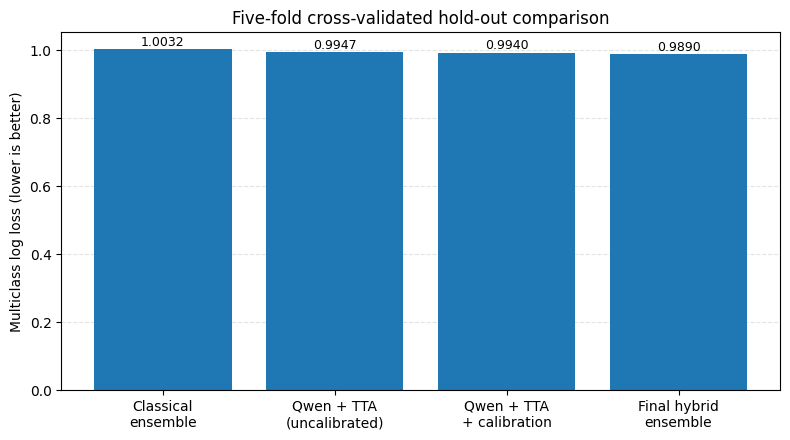

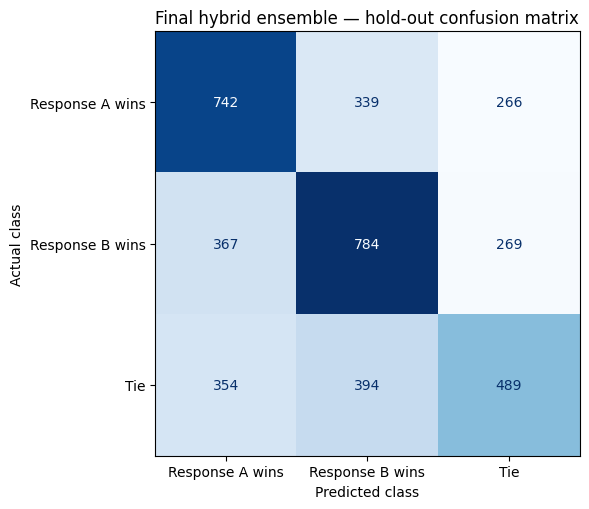

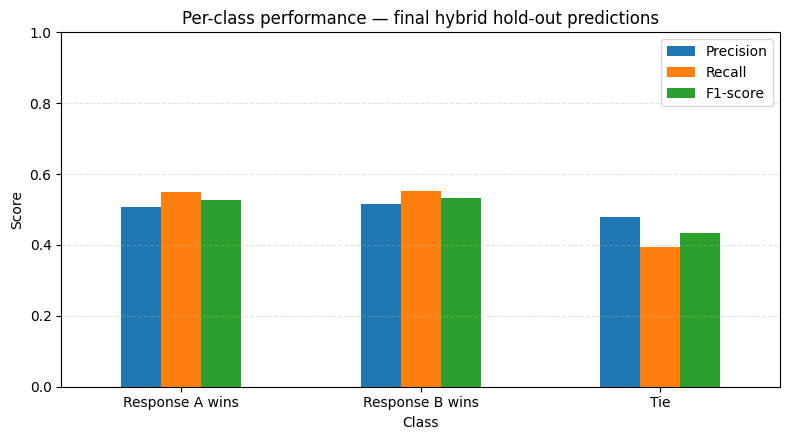

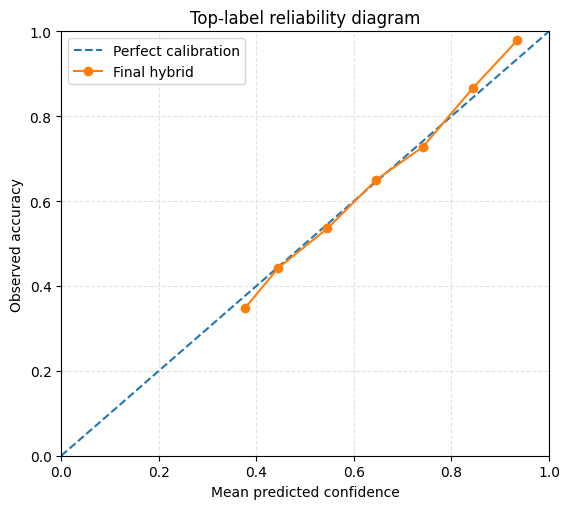

Figures saved under: /kaggle/working


In [19]:
# ================================================================
# EXTRA EVALUATION CELL 2: Report figures from actual model outputs
# All plots below are generated from the executed notebook predictions.
# ================================================================
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

# Figure 1: Comparable hold-out log-loss comparison.
# The predictions come from the five-fold hold-out CV in original cell 29.
if "cv" in globals() and "yh" in globals():
    holdout_logloss = {
        "Classical\nensemble": ll(ph_cls, yh),
        "Qwen + TTA\n(uncalibrated)": ll(cv["llm_raw"], yh),
        "Qwen + TTA\n+ calibration": ll(cv["llm_cal"], yh),
        "Final hybrid\nensemble": ll(cv["blend"], yh),
    }
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(list(holdout_logloss.keys()), list(holdout_logloss.values()))
    ax.set_ylabel("Multiclass log loss (lower is better)")
    ax.set_title("Five-fold cross-validated hold-out comparison")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)
    for bar, val in zip(bars, holdout_logloss.values()):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.0008,
                f"{val:.4f}", ha="center", va="bottom", fontsize=9)
    fig.tight_layout()
    plt.show()
    fig.savefig(f"{WORK}/figure_holdout_logloss_comparison.png", dpi=300, bbox_inches="tight")
else:
    print("Hold-out predictions are unavailable; skipping hold-out comparison plot.")

# Figure 2: Confusion matrix for the final hybrid model.
# This is based on cross-validated hold-out predictions, not test labels.
if "cv" in globals() and "yh" in globals():
    yhat_final_holdout = cv["blend"].argmax(axis=1)
    cm = confusion_matrix(yh, yhat_final_holdout, labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title("Final hybrid ensemble — hold-out confusion matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    fig.tight_layout()
    plt.show()
    fig.savefig(f"{WORK}/figure_final_hybrid_confusion_matrix.png", dpi=300, bbox_inches="tight")

# Figure 3: Per-class precision, recall and F1-score.
if "per_class_metrics_df" in globals():
    plot_df = per_class_metrics_df.set_index("Class")[["Precision", "Recall", "F1-score"]]
    ax = plot_df.plot(kind="bar", figsize=(8, 4.5), ylim=(0, 1), rot=0)
    ax.set_ylabel("Score")
    ax.set_title("Per-class performance — final hybrid hold-out predictions")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()
    ax.figure.savefig(f"{WORK}/figure_per_class_precision_recall_f1.png", dpi=300, bbox_inches="tight")

# Figure 4: Top-label reliability diagram for final hybrid hold-out predictions.
# Points closer to the diagonal indicate better top-label calibration.
if "cv" in globals() and "yh" in globals():
    confidence = cv["blend"].max(axis=1)
    predicted = cv["blend"].argmax(axis=1)
    correct = (predicted == yh).astype(int)
    bin_edges = np.linspace(0, 1, 11)
    bin_conf, bin_acc, bin_n = [], [], []
    for j in range(10):
        mask = (confidence >= bin_edges[j]) & (
            (confidence < bin_edges[j+1]) if j < 9 else (confidence <= bin_edges[j+1])
        )
        if mask.any():
            bin_conf.append(confidence[mask].mean())
            bin_acc.append(correct[mask].mean())
            bin_n.append(mask.sum())
    fig, ax = plt.subplots(figsize=(5.8, 5.2))
    ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
    ax.plot(bin_conf, bin_acc, marker="o", label="Final hybrid")
    ax.set_xlabel("Mean predicted confidence")
    ax.set_ylabel("Observed accuracy")
    ax.set_title("Top-label reliability diagram")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend()
    fig.tight_layout()
    plt.show()
    fig.savefig(f"{WORK}/figure_final_hybrid_reliability.png", dpi=300, bbox_inches="tight")

print(f"Figures saved under: {WORK}")


In [20]:
    # ================================================================
# EXTRA EVALUATION CELL 3: Baselines, probability checks and run summary
# ================================================================
from sklearn.metrics import accuracy_score, f1_score

# Uniform-probability baseline on the full OOF training labels.
uniform_oof = np.full((len(y), 3), 1.0 / 3.0, dtype=float)

# Majority-class baseline: predicts the most frequent training class
# with probability 1 for that class. For log loss, use a smoothed prior
# probability baseline to avoid infinite loss.
class_counts = np.bincount(y, minlength=3)
class_prior = class_counts / class_counts.sum()
prior_oof = np.tile(class_prior, (len(y), 1))

best_classical_name = min(names, key=lambda n: ll(oof[n], y))
best_classical_prob = oof[best_classical_name]
baseline_df = pd.DataFrame([
    {
        "Baseline / model": "Uniform probabilities",
        "Log loss": ll(uniform_oof, y),
        "Accuracy": accuracy_score(y, uniform_oof.argmax(axis=1)),
        "Macro F1": f1_score(y, uniform_oof.argmax(axis=1), average="macro", zero_division=0)
    },
    {
        "Baseline / model": f"Best individual OOF model ({best_classical_name})",
        "Log loss": ll(best_classical_prob, y),
        "Accuracy": accuracy_score(y, best_classical_prob.argmax(axis=1)),
        "Macro F1": f1_score(y, best_classical_prob.argmax(axis=1), average="macro", zero_division=0)
    },
    {
        "Baseline / model": "Classical OOF blend",
        "Log loss": ll(held, y),
        "Accuracy": accuracy_score(y, held.argmax(axis=1)),
        "Macro F1": f1_score(y, held.argmax(axis=1), average="macro", zero_division=0)
    }
])
print("FULL OOF BASELINE COMPARISON")
display(baseline_df.round(4))
baseline_df.to_csv(f"{WORK}/baseline_comparison_for_report.csv", index=False)

# Verify test submission probabilities. There are no test labels, so do NOT
# calculate accuracy/F1/log loss on test.csv.
submission_check = pd.DataFrame({
    "Check": [
        "Submission rows equal test rows",
        "IDs match test order",
        "All probabilities finite",
        "All probabilities non-negative",
        "Each row sums to one"
    ],
    "Passed": [
        len(sub) == len(test),
        np.array_equal(sub["id"].values, test["id"].values),
        np.isfinite(p_final).all(),
        (p_final >= 0).all(),
        np.allclose(p_final.sum(axis=1), 1.0, atol=1e-5)
    ]
})
print("\nFINAL TEST SUBMISSION VALIDATION (NOT PREDICTIVE PERFORMANCE)")
display(submission_check)

print("\nREPORTING NOTES")
print("- Report log loss as the primary competition metric.")
print("- Report accuracy, macro-F1, per-class precision/recall/F1, and confusion matrix as secondary hold-out metrics.")
print("- Use the hold-out cross-validated predictions for LLM/hybrid hold-out figures.")
print("- The test file has no ground-truth labels; do not calculate test accuracy/F1.")
print("- Kaggle score 0.99361 should be reported separately from internal validation and labelled public/private only after checking Kaggle.")


FULL OOF BASELINE COMPARISON


,Baseline / model,Log loss,Accuracy,Macro F1
0,Uniform probabilities,1.0986,0.3491,0.1725
1,Best individual OOF model (lgbm_A),1.0095,0.4903,0.4828
2,Classical OOF blend,1.0075,0.4922,0.4838



FINAL TEST SUBMISSION VALIDATION (NOT PREDICTIVE PERFORMANCE)


,Check,Passed
0,Submission rows equal test rows,True
1,IDs match test order,True
2,All probabilities finite,True
3,All probabilities non-negative,True
4,Each row sums to one,True



REPORTING NOTES
- Report log loss as the primary competition metric.
- Report accuracy, macro-F1, per-class precision/recall/F1, and confusion matrix as secondary hold-out metrics.
- Use the hold-out cross-validated predictions for LLM/hybrid hold-out figures.
- The test file has no ground-truth labels; do not calculate test accuracy/F1.
- Kaggle score 0.99361 should be reported separately from internal validation and labelled public/private only after checking Kaggle.
